# 06. Head-only와 Layer4 + Head 전이학습 비교
수정한 `06_transfer.py`의 실제 재실행 결과 `outputs/transfer_comparison.csv`를 바탕으로 학습 가능 파라미터 수, 검증 손실·정확도, 학습 시간을 비교합니다.

**관측 결과:** Head-only는 1,026개, Layer4 + Head는 8,394,754개를 학습합니다. 두 조건 모두 검증 정확도 100%이며, 이번 실행에서 Layer4 + Head의 검증 손실이 더 낮았습니다.

## 0. 작업 전 준비사항
PyTorch, torchvision, pandas, matplotlib이 설치된 커널에서 **Run All**로 실행합니다. 이 노트북은 사용자가 실행한 CSV를 읽으며, 사전학습 가중치 다운로드나 재학습을 수행하지 않습니다. 비교 표와 그림은 `02_응용/docs/outputs`에 저장합니다.

아래 파라미터 구조 검증은 `weights=None`으로 모델 구조만 생성합니다. 이는 파라미터 개수 확인 전용이며 성능 평가에는 사용하지 않습니다. 보고하는 손실·정확도는 **IMAGENET1K_V1 사전학습 가중치로 실행한 CSV**에서만 가져옵니다.

In [1]:
%matplotlib inline
from pathlib import Path
import torch
from torch import nn
from torchvision.models import resnet18
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
day_root = next((candidate for parent in (cwd, *cwd.parents)
                 for candidate in (parent / "20261102", parent)
                 if (candidate / "02_응용" / "06_transfer.py").is_file()), None)
if day_root is None:
    raise FileNotFoundError("이 저장소 안에서 실행하세요.")
source = day_root / "02_응용" / "outputs" / "transfer_comparison.csv"
results = pd.read_csv(source)
assert results["mode"].value_counts().to_dict() == {"head": 1, "partial": 1}
assert (results["pretrained"] == "IMAGENET1K_V1").all()
assert (results["image_size"] == 224).all()
assert (results["epochs"] == 1).all()
results = results.set_index("mode").loc[["head", "partial"]].reset_index()
out = day_root / "02_응용" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)
print(results.to_string(index=False))
results.to_csv(out / "transfer_comparison_record.csv", index=False)

   mode    pretrained  image_size  epochs  trainable_params  valid_loss  valid_accuracy  training_seconds
   head IMAGENET1K_V1         224       1              1026    0.221818             1.0          2.257624
partial IMAGENET1K_V1         224       1           8394754    0.000217             1.0          3.153150


## 1. 두 조건에서 무엇을 학습하나요?
ResNet18의 ImageNet 특징 추출 가중치를 불러온 뒤 모든 파라미터를 동결하고, 마지막 분류층 `fc`를 2클래스용으로 교체합니다. 새 `fc`는 기본적으로 `requires_grad=True`입니다.

| 항목 | Head-only (`head`) | Layer4 + Head (`partial`) |
| --- | --- | --- |
| 학습하는 범위 | 새 `fc`만 | 마지막 특징 추출 블록 `layer4`와 새 `fc` |
| 앞쪽 특징 추출부 | 동결 | layer4 이전까지 동결 |
| fc 학습률 | 0.001 | 0.001 |
| layer4 학습률 | 학습하지 않음 | 0.0001 |
| 옵티마이저 | AdamW, weight_decay=0.0001 | 동일 |
| 입력·학습량 | 224×224, 배치 4, 1 epoch | 동일 |
| BatchNorm running 통계 | 고정 | 고정 |

각 조건 시작 시 seed=42로 모델과 학습 데이터 순서를 맞춥니다. `weights.transforms()`로 사전학습 모델의 Resize·Crop·정규화 전처리를 두 데이터셋에 적용합니다. 입력 shape는 `[B, 3, 224, 224]`입니다.

### A06 변경의 의미
```python
if mode == "partial":
    for param in model.layer4.parameters():
        param.requires_grad = True
```

이 변경으로 layer4에도 기울기가 계산되고 옵티마이저가 해당 파라미터를 갱신합니다. 이전처럼 False이면 옵티마이저 그룹에 layer4를 넣더라도 실제로 학습되지 않아 두 조건 모두 fc만 학습하게 됩니다.

## 2. Trainable parameters 계산
`trainable_params`는 모델 전체 파라미터 중 `requires_grad=True`인 원소 수입니다.

```python
sum(p.numel() for p in model.parameters() if p.requires_grad)
```

- fc의 입력 특징 수는 512, 출력 클래스 수는 2이므로 `512 × 2 + 2 = 1,026`개입니다.
- layer4의 파라미터는 `8,393,728`개입니다. 합성곱 가중치와 BatchNorm의 학습 가능한 scale·bias를 포함합니다.
- Layer4 + Head는 `8,393,728 + 1,026 = 8,394,754`개입니다.

입력 이미지 크기와 배치 크기가 바뀌어도 이 모델 구조의 파라미터 수는 그대로입니다. 파라미터 증가 비율이 실제 실행 시간 증가 비율과 같은 것은 아닙니다.

In [2]:
# 구조의 파라미터 개수만 확인합니다. 이 모델로 성능을 측정하지 않습니다.
structure = resnet18(weights=None)
structure.fc = nn.Linear(structure.fc.in_features, 2)
fc_count = sum(p.numel() for p in structure.fc.parameters())
layer4_count = sum(p.numel() for p in structure.layer4.parameters())
expected = {"head": fc_count, "partial": fc_count + layer4_count}
for row in results.itertuples():
    assert row.trainable_params == expected[row.mode]
assert fc_count == 1026
assert layer4_count == 8393728
print("fc:", f"{fc_count:,}")
print("layer4:", f"{layer4_count:,}")
print("layer4 + fc:", f"{fc_count + layer4_count:,}")
print("학습 가능 파라미터 배수:", f"{(fc_count + layer4_count) / fc_count:,.2f}배")
del structure

fc: 1,026
layer4: 8,393,728
layer4 + fc: 8,394,754
학습 가능 파라미터 배수: 8,182.02배


## 3. 파라미터 수·검증 성능·학습 시간 비교
파라미터 수와 손실은 차이가 커서 로그 축을 사용합니다. 정확도는 두 조건 모두 100%여서 이번 표본에서는 우열을 가릴 수 없습니다. 학습 시간은 모델 생성·가중치 다운로드와 검증을 제외한 원본 학습 루프의 1회 측정값입니다. 데이터 읽기·전처리·순전파·역전파·갱신 시간이 포함되며, 반복 측정이나 워밍업을 한 벤치마크는 아닙니다.

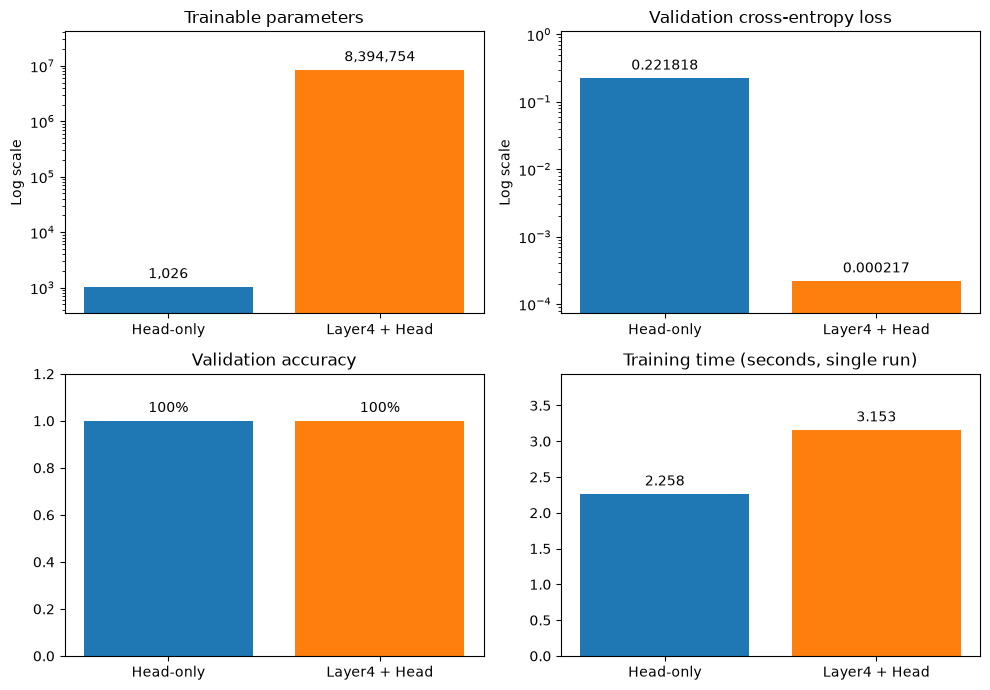

검증 손실: Head-only 0.221817742 → Layer4 + Head 0.000217168
학습 시간: 2.258초 → 3.153초
학습 시간 비율(이번 실행): 1.40배
정확도: 100% / 100%


In [3]:
labels = ["Head-only", "Layer4 + Head"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
settings = [("trainable_params", "Trainable parameters", True),
            ("valid_loss", "Validation cross-entropy loss", True),
            ("valid_accuracy", "Validation accuracy", False),
            ("training_seconds", "Training time (seconds, single run)", False)]
for ax, (key, title, logscale) in zip(axes.flat, settings):
    values = results[key].to_numpy()
    bars = ax.bar(labels, values, color=["tab:blue", "tab:orange"])
    if logscale:
        ax.set_yscale("log")
        ax.set_ylim(min(values) / 3, max(values) * 5)
        ax.set_ylabel("Log scale")
    else:
        ax.set_ylim(0, 1.2 if key == "valid_accuracy" else max(values) * 1.25)
    display = ([f"{int(v):,}" for v in values] if key == "trainable_params" else
               [f"{v:.0%}" for v in values] if key == "valid_accuracy" else
               [f"{v:.6f}" for v in values] if key == "valid_loss" else
               [f"{v:.3f}" for v in values])
    ax.bar_label(bars, labels=display, padding=4)
    ax.set_title(title)
fig.tight_layout()
fig.savefig(out / "transfer_head_vs_layer4.png", dpi=140)
plt.show()
plt.close(fig)

head, partial = results.iloc[0], results.iloc[1]
print("검증 손실: Head-only", f"{head.valid_loss:.9f}", "→ Layer4 + Head", f"{partial.valid_loss:.9f}")
print("학습 시간:", f"{head.training_seconds:.3f}초 → {partial.training_seconds:.3f}초")
print("학습 시간 비율(이번 실행):", f"{partial.training_seconds / head.training_seconds:.2f}배")
print("정확도:", f"{head.valid_accuracy:.0%} / {partial.valid_accuracy:.0%}")

## 4. BatchNorm 동결과 학습 가능 여부는 별개
`requires_grad=False`는 가중치·편향의 기울기 계산을 막습니다. BatchNorm의 `running_mean`·`running_var`는 파라미터가 아닌 버퍼이며, train 모드에서는 이 통계가 갱신될 수 있으므로 requires_grad만으로 고정되지 않습니다.

06번은 `model.eval()`로 시작하고 partial에서는 `layer4.train()` 뒤 layer4 내부 BatchNorm을 다시 `eval()`로 설정해 running 통계를 고정합니다. **eval 모드가 역전파 자체를 막지는 않습니다.** partial의 BatchNorm scale·bias는 requires_grad=True이므로 통계를 고정한 상태에서도 학습 가능합니다. fc도 eval 여부와 별개로 기울기를 계산할 수 있습니다. `torch.no_grad()`는 검증 루프에만 적용합니다.

## 5. 이번 결과의 해석
현재 저장된 실행 결과는 다음과 같습니다.

| 조건 | 학습 가능 파라미터 | valid loss | valid accuracy | 학습 시간 |
| --- | --- | --- | --- | --- |
| Head-only | 1,026 | 0.221817742 | 100% | 2.258초 |
| Layer4 + Head | 8,394,754 | 0.000217168 | 100% | 3.153초 |

Head-only는 기존 특징 추출부를 유지하고 마지막 분류 경계만 학습합니다. Layer4 + Head는 높은 수준의 특징 추출부까지 현재 줄무늬 데이터에 맞게 조정합니다. 이번 실행에서는 Layer4 + Head의 검증 손실이 더 낮고 학습 시간은 더 길었습니다.

정확도는 두 조건 모두 같지만 손실은 다릅니다. 교차 엔트로피는 정답 클래스에 부여한 확률을 반영하므로 같은 정답 여부에서도 차이가 날 수 있습니다. 낮은 손실만으로 확률 보정이나 모든 데이터에서의 일반화 성능이 더 좋다고 결론 낼 수는 없습니다.

이번 결과는 **간단한 합성 이미지의 소표본, seed=42, 1 epoch**에서 얻었습니다. 1 epoch는 학습 경로를 확인하는 조건이며 Layer4 + Head가 항상 우수하다는 근거는 아닙니다. 더 긴 학습에서의 과적합과 여러 seed·별도 test 성능을 확인해야 합니다. 위 표와 그림은 현재 CSV의 실행 기록이며 CSV를 바꾸면 코드 셀 출력이 갱신되므로 본문의 실행 기록도 함께 갱신해야 합니다.

### 직접 확인해 볼 내용
- 학습 epoch를 늘려 두 조건의 train·valid loss가 어떻게 달라지는지 비교합니다.
- layer4의 학습률을 바꾸되 fc 학습률과 다른 조건은 고정합니다.
- 여러 seed에서 결과와 학습 시간을 반복 측정합니다.
- 개선 설정은 valid로 고른 뒤 별도 test로 최종 성능을 평가합니다.